# IFN680 Project 7 — Improving DDPM

## Task 1 — Model Training

This notebook implements and trains two conditional Denoising Diffusion Probabilistic Models (DDPMs) on the supplied custom MNIST dataset:

1. a baseline DDPM using the **linear beta schedule** from the Week 9 tutorial; and
2. a DDPM using a **cosine beta schedule**.

The project investigates the hypothesis that a cosine noise schedule can produce high-quality generated samples using fewer diffusion time steps than a linear schedule.

To support a controlled comparison, both models will use the same dataset, conditional U-Net architecture, training objective and shared training configuration. The primary experimental difference is the diffusion noise schedule.

## 1. Project Setup and Reproducibility

This section establishes the notebook environment and shared experiment configuration.

Where practical, fixed random seeds are used to improve reproducibility between runs. The available compute device is also detected so that model training can use GPU acceleration when available.

In [1]:
# Standard library
import random
import time
from pathlib import Path

# Numerical / plotting
import numpy as np
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Save linear model initial state (for later)
import copy

from tqdm.auto import tqdm

### 1.1 Reproducibility

In [2]:
# Reproducibility
SEED = 42


def reset_random_seeds(seed=SEED):
    """
    Reset every random number generator used by the training pipeline.

    Called immediately before each experiment so that the linear and cosine
    runs receive equivalent random sequences for DataLoader shuffling,
    sampled timesteps and Gaussian noise draws.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


reset_random_seeds()

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.13.0+cu126
Device: cuda
GPU: NVIDIA A16-4Q


### 1.2 Shared experiment configuration

The two DDPM models will use shared training and model settings wherever possible so that the effect of the noise schedule can be investigated under comparable conditions.

Schedule-specific parameters will be introduced alongside the linear and cosine schedule implementations.

In [3]:
# Paths
# The supplied dataset is named mnist_custom.pt, but download tooling can
# append a suffix. Accept either name so the notebook runs unmodified.
DATA_PATH_CANDIDATES = [
    Path("mnist_custom.pt"),
    Path("mnist_custom-3.pt"),
]

DATA_PATH = next(
    (path for path in DATA_PATH_CANDIDATES if path.exists()),
    DATA_PATH_CANDIDATES[0]
)

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset / model constants
NUM_CLASSES = 10
IMAGE_SIZE = 20
IMAGE_CHANNELS = 1
UNET_CHANNELS = 32

# Diffusion configuration
TIMESTEPS = 1000

# DataLoader configuration
BATCH_SIZE = 128

print(f"Dataset path: {DATA_PATH}")
print(f"Checkpoint directory: {CHECKPOINT_DIR}")
print(f"Image dimensions: {IMAGE_CHANNELS} x {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Diffusion timesteps: {TIMESTEPS}")
print(f"Batch size: {BATCH_SIZE}")

Dataset path: mnist_custom-3.pt
Checkpoint directory: checkpoints
Image dimensions: 1 x 20 x 20
Diffusion timesteps: 1000
Batch size: 128


## 2. Dataset Loading and Validation

Project 7 uses the supplied `mnist_custom.pt` dataset rather than the standard `torchvision` MNIST dataset.

Before constructing the training pipeline, the dataset is inspected to confirm:

- the available dictionary keys;
- training and testing tensor shapes;
- tensor data types;
- image value ranges;
- label values; and
- the visual appearance of representative samples.

This ensures that the custom dataset is transformed into the representation expected by the DDPM without making assumptions based on the standard MNIST loader.

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the dataset at: {DATA_PATH.resolve()}"
    )

# following blocks to see if data errors
print(f"DATA_PATH:     {DATA_PATH}")
print(f"Absolute path: {DATA_PATH.resolve()}")
print(f"Exists:        {DATA_PATH.exists()}")
print(f"Is file:       {DATA_PATH.is_file()}")

with open(DATA_PATH, "rb") as f:
    header = f.read(16)

print(f"First 16 bytes: {header}")



DATA_PATH:     mnist_custom-3.pt
Absolute path: /home/n10755306/ifn680/IFN680_Sam/Assessment1/Project7/mnist_custom-3.pt
Exists:        True
Is file:       True
First 16 bytes: b'PK\x03\x04\x00\x00\x08\x08\x00\x00\x00\x00\x00\x00\x00\x00'


In [5]:
# if failures here, mostly likely a data corruption error

if DATA_PATH.exists():
    print(f"File size:     {DATA_PATH.stat().st_size:,} bytes")

data = torch.load(DATA_PATH)

print(f"Loaded: {DATA_PATH}")
print(f"Object type: {type(data)}")

if isinstance(data, dict):
    print(f"Keys: {list(data.keys())}")

File size:     112,562,040 bytes
Loaded: mnist_custom-3.pt
Object type: <class 'dict'>
Keys: ['train_images', 'train_labels', 'test_images', 'test_labels']


### 2.1 Extract Tensors

In [6]:

train_images = data["train_images"]
train_labels = data["train_labels"]
test_images = data["test_images"]
test_labels = data["test_labels"]

print("Training:")
print(f"  Images: {train_images.shape}")
print(f"  Labels: {train_labels.shape}")

print("\nTesting:")
print(f"  Images: {test_images.shape}")
print(f"  Labels: {test_labels.shape}")

Training:
  Images: torch.Size([60000, 1, 20, 20])
  Labels: torch.Size([60000])

Testing:
  Images: torch.Size([10000, 1, 20, 20])
  Labels: torch.Size([10000])


### 2.2 Inspect extracted tensor's properties

In [7]:
def describe_tensor(name, tensor):
    print(f"{name}")
    print(f"  Shape: {tuple(tensor.shape)}")
    print(f"  Dtype: {tensor.dtype}")
    print(f"  Min:   {tensor.min().item()}")
    print(f"  Max:   {tensor.max().item()}")
    print()


describe_tensor("Train images", train_images)
describe_tensor("Train labels", train_labels)
describe_tensor("Test images", test_images)
describe_tensor("Test labels", test_labels)

Train images
  Shape: (60000, 1, 20, 20)
  Dtype: torch.float32
  Min:   0.0
  Max:   1.0

Train labels
  Shape: (60000,)
  Dtype: torch.int64
  Min:   0
  Max:   9

Test images
  Shape: (10000, 1, 20, 20)
  Dtype: torch.float32
  Min:   0.0
  Max:   1.0

Test labels
  Shape: (10000,)
  Dtype: torch.int64
  Min:   0
  Max:   9



Validate data labels

In [8]:
train_classes = torch.unique(train_labels)
test_classes = torch.unique(test_labels)

print(f"Training classes: {train_classes.tolist()}")
print(f"Testing classes:  {test_classes.tolist()}")

assert len(train_images) == len(train_labels), (
    "Training image and label counts do not match."
)

assert len(test_images) == len(test_labels), (
    "Testing image and label counts do not match."
)

assert set(train_classes.tolist()) == set(range(NUM_CLASSES)), (
    "Training labels do not contain exactly classes 0–9."
)

assert set(test_classes.tolist()) == set(range(NUM_CLASSES)), (
    "Testing labels do not contain exactly classes 0–9."
)

# Confirm the configured image dimensions match the supplied tensors.
assert train_images.shape[1:] == (IMAGE_CHANNELS, IMAGE_SIZE, IMAGE_SIZE), (
    f"Expected images of shape "
    f"({IMAGE_CHANNELS}, {IMAGE_SIZE}, {IMAGE_SIZE}), "
    f"found {tuple(train_images.shape[1:])}."
)

assert test_images.shape[1:] == train_images.shape[1:], (
    "Training and testing image dimensions differ."
)

print("\nDataset label validation passed.")

Training classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Testing classes:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Dataset label validation passed.


LCass Counts

In [9]:
train_counts = torch.bincount(train_labels.long(), minlength=NUM_CLASSES)
test_counts = torch.bincount(test_labels.long(), minlength=NUM_CLASSES)

print("Class counts")
print("-" * 34)
print(f"{'Digit':<8}{'Train':>10}{'Test':>10}")

for digit in range(NUM_CLASSES):
    print(
        f"{digit:<8}"
        f"{train_counts[digit].item():>10}"
        f"{test_counts[digit].item():>10}"
    )

Class counts
----------------------------------
Digit        Train      Test
0             5923       980
1             6742      1135
2             5958      1032
3             6131      1010
4             5842       982
5             5421       892
6             5918       958
7             6265      1028
8             5851       974
9             5949      1009


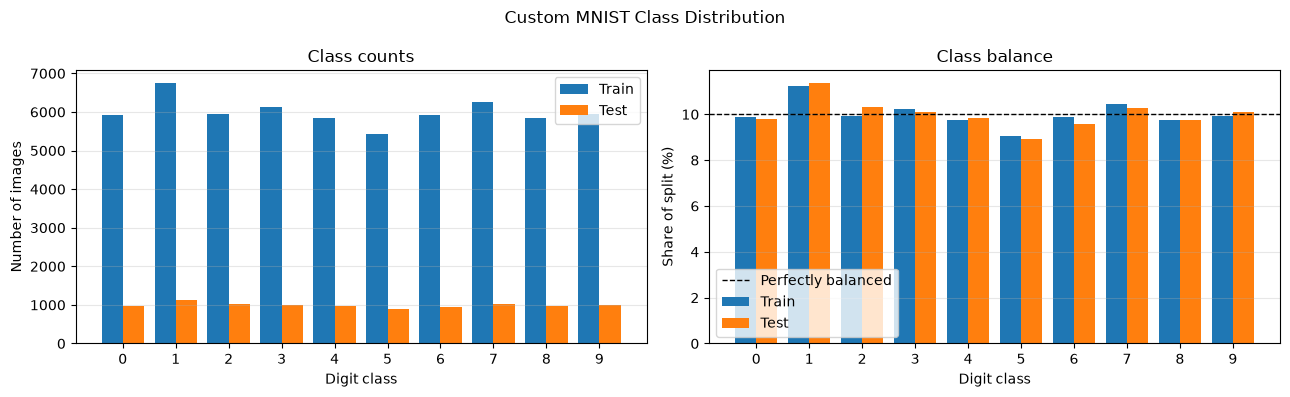

Train share range: 9.04% to 11.24%
Test share range:  8.92% to 11.35%


In [10]:
digits = np.arange(NUM_CLASSES)
bar_width = 0.4

train_counts_np = train_counts.numpy()
test_counts_np = test_counts.numpy()

fig, (ax_counts, ax_share) = plt.subplots(1, 2, figsize=(13, 4))

# Absolute counts per class.
ax_counts.bar(
    digits - bar_width / 2,
    train_counts_np,
    width=bar_width,
    label="Train"
)

ax_counts.bar(
    digits + bar_width / 2,
    test_counts_np,
    width=bar_width,
    label="Test"
)

ax_counts.set_xlabel("Digit class")
ax_counts.set_ylabel("Number of images")
ax_counts.set_title("Class counts")
ax_counts.set_xticks(digits)
ax_counts.legend()
ax_counts.grid(alpha=0.3, axis="y")

# Share of each split, so the two splits can be compared on one scale.
train_share = 100 * train_counts_np / train_counts_np.sum()
test_share = 100 * test_counts_np / test_counts_np.sum()

ax_share.bar(
    digits - bar_width / 2,
    train_share,
    width=bar_width,
    label="Train"
)

ax_share.bar(
    digits + bar_width / 2,
    test_share,
    width=bar_width,
    label="Test"
)

ax_share.axhline(
    100 / NUM_CLASSES,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Perfectly balanced"
)

ax_share.set_xlabel("Digit class")
ax_share.set_ylabel("Share of split (%)")
ax_share.set_title("Class balance")
ax_share.set_xticks(digits)
ax_share.legend()
ax_share.grid(alpha=0.3, axis="y")

plt.suptitle("Custom MNIST Class Distribution")
plt.tight_layout()
plt.show()

print(
    f"Train share range: "
    f"{train_share.min():.2f}% to {train_share.max():.2f}%"
)

print(
    f"Test share range:  "
    f"{test_share.min():.2f}% to {test_share.max():.2f}%"
)

### 2.3 Visual dataset sanity check

Representative training samples are displayed to confirm that the supplied tensors contain the expected MNIST-style digit images and to identify their image dimensions before preprocessing.

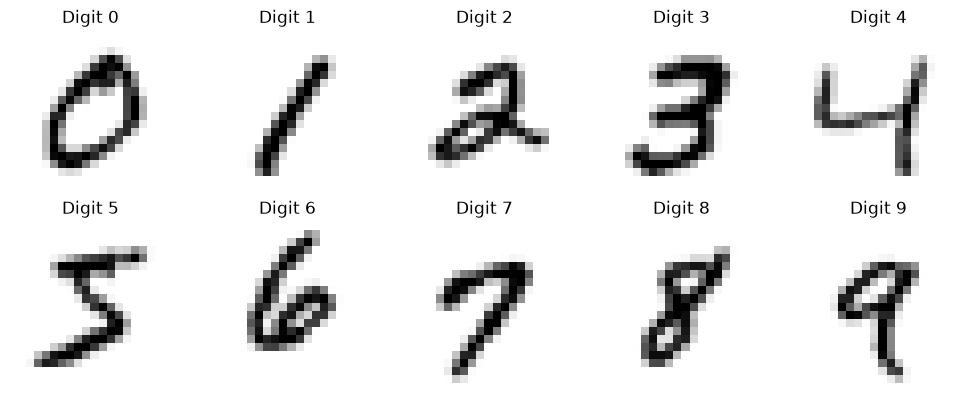

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for digit, ax in enumerate(axes.flat):
    index = (train_labels == digit).nonzero(as_tuple=True)[0][0].item()
    image = train_images[index]

    # Remove a single channel dimension for plotting if present.
    if image.ndim == 3 and image.shape[0] == 1:
        image = image.squeeze(0)

    ax.imshow(image.cpu(), cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.4 Scale Images

In [12]:
# Scale image values from [0, 1] to [-1, 1].
train_images_scaled = train_images * 2.0 - 1.0
test_images_scaled = test_images * 2.0 - 1.0

print(
    f"Train range: "
    f"[{train_images_scaled.min().item():.1f}, "
    f"{train_images_scaled.max().item():.1f}]"
)

print(
    f"Test range:  "
    f"[{test_images_scaled.min().item():.1f}, "
    f"{test_images_scaled.max().item():.1f}]"
)

print(f"Train shape: {tuple(train_images_scaled.shape)}")
print(f"Test shape:  {tuple(test_images_scaled.shape)}")

Train range: [-1.0, 1.0]
Test range:  [-1.0, 1.0]
Train shape: (60000, 1, 20, 20)
Test shape:  (10000, 1, 20, 20)


### 2.5 Build Datasets / loaders

In [13]:
train_dataset = TensorDataset(
    train_images_scaled,
    train_labels
)

test_dataset = TensorDataset(
    test_images_scaled,
    test_labels
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Training samples: {len(train_dataset):,}")
print(f"Testing samples:  {len(test_dataset):,}")
print(f"Training batches: {len(train_loader):,}")
print(f"Testing batches:  {len(test_loader):,}")

Training samples: 60,000
Testing samples:  10,000
Training batches: 469
Testing batches:  79


verify one batch

In [14]:
batch_images, batch_labels = next(iter(train_loader))

print(f"Image batch shape: {batch_images.shape}")
print(f"Label batch shape: {batch_labels.shape}")
print(f"Image dtype:       {batch_images.dtype}")
print(f"Label dtype:       {batch_labels.dtype}")
print(
    f"Image range:       "
    f"[{batch_images.min().item():.1f}, "
    f"{batch_images.max().item():.1f}]"
)

Image batch shape: torch.Size([128, 1, 20, 20])
Label batch shape: torch.Size([128])
Image dtype:       torch.float32
Label dtype:       torch.int64
Image range:       [-1.0, 1.0]


## 3. Linear Noise Schedule

The DDPM forward process progressively corrupts a clean image $x_0$ by adding Gaussian noise over $T$ diffusion time steps.

At each timestep, the variance schedule defines a noise value $\beta_t$. From this:

$$
\alpha_t = 1 - \beta_t
$$

and the cumulative product

$$
\bar{\alpha}_t = \prod_{s=1}^{t}\alpha_s
$$

describes how much of the original signal remains at timestep $t$.

The Week 9 tutorial uses a **linear beta schedule**, in which $\beta_t$ increases linearly from a small starting value to a larger final value. This schedule is retained as the baseline for Project 7.

In [15]:
# CITE: TUTORIAL 9 SOLUTION
timesteps = TIMESTEPS

def linear_beta_schedule(timesteps, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start,beta_end, timesteps)

linear_betas = linear_beta_schedule(timesteps).to(device)
linear_alphas = 1.0 - linear_betas
linear_alpha_bars = torch.cumprod(linear_alphas, dim=0)

## 4. Cosine Noise Schedule

The second DDPM uses a **cosine noise schedule** rather than the linear schedule used by the tutorial baseline.

Instead of defining $\beta_t$ directly as a linear sequence, the cosine schedule first defines the cumulative signal retention $\bar{\alpha}_t$ using a cosine function. The corresponding $\beta_t$ values are then derived from consecutive cumulative values.

The schedule is defined as:

$$
\bar{\alpha}_t =
\frac{
\cos^2\left(
\frac{t/T+s}{1+s}\frac{\pi}{2}
\right)
}{
\cos^2\left(
\frac{s}{1+s}\frac{\pi}{2}
\right)
}
$$

where $T$ is the total number of diffusion timesteps and $s$ is a small offset.

The resulting beta values are obtained from:

$$
\beta_t =
1 -
\frac{\bar{\alpha}_t}
{\bar{\alpha}_{t-1}}
$$

and clipped to prevent numerically problematic values close to 1.

This changes how quickly information is removed from the original image across diffusion time while leaving the underlying DDPM training objective unchanged.

In [16]:
def cosine_beta_schedule(timesteps, s=0.008):
    """
    Create a cosine beta schedule for DDPM.

    The schedule defines alpha_bar using a cosine function and derives
    beta_t from the ratio between consecutive alpha_bar values.
    """
    steps = timesteps + 1
    x = torch.linspace(0, timesteps, steps)

    alpha_bars = torch.cos(
        ((x / timesteps + s) / (1 + s)) * torch.pi / 2
    ) ** 2

    # Normalise so alpha_bar starts at 1.
    alpha_bars = alpha_bars / alpha_bars[0]

    betas = 1.0 - (alpha_bars[1:] / alpha_bars[:-1])

    # Avoid beta values reaching 1.
    return torch.clamp(betas, min=1e-4, max=0.999)


cosine_betas = cosine_beta_schedule(timesteps).to(device)
cosine_alphas = 1.0 - cosine_betas
cosine_alpha_bars = torch.cumprod(cosine_alphas, dim=0)

### 4.1 validate the schedulers

In [17]:
print("Linear schedule")
print(f"  Shape:          {linear_betas.shape}")
print(f"  Beta range:     {linear_betas.min().item():.6f} to "
      f"{linear_betas.max().item():.6f}")
print(f"  Final alpha_bar: {linear_alpha_bars[-1].item():.8f}")

print("\nCosine schedule")
print(f"  Shape:          {cosine_betas.shape}")
print(f"  Beta range:     {cosine_betas.min().item():.6f} to "
      f"{cosine_betas.max().item():.6f}")
print(f"  Final alpha_bar: {cosine_alpha_bars[-1].item():.8f}")

assert linear_betas.shape == cosine_betas.shape
assert torch.all(linear_betas > 0)
assert torch.all(linear_betas < 1)
assert torch.all(cosine_betas > 0)
assert torch.all(cosine_betas < 1)

print("\nSchedule validation passed.")

Linear schedule
  Shape:          torch.Size([1000])
  Beta range:     0.000100 to 0.020000
  Final alpha_bar: 0.00004036

Cosine schedule
  Shape:          torch.Size([1000])
  Beta range:     0.000100 to 0.999000
  Final alpha_bar: 0.00000000

Schedule validation passed.


## 5. Visualise and Validate the Noise Schedules

Before training, the linear and cosine schedules are compared to verify how they distribute noise across the 1,000-step forward diffusion process.

Two quantities are examined:

- $\beta_t$, which controls the amount of noise introduced at each diffusion step; and
- $\bar{\alpha}_t$, which represents the cumulative proportion of the original signal retained as diffusion progresses.

This comparison verifies that the two models will use meaningfully different noise trajectories while retaining the same total number of diffusion timesteps.

### 5.1 Comapre beta schedules

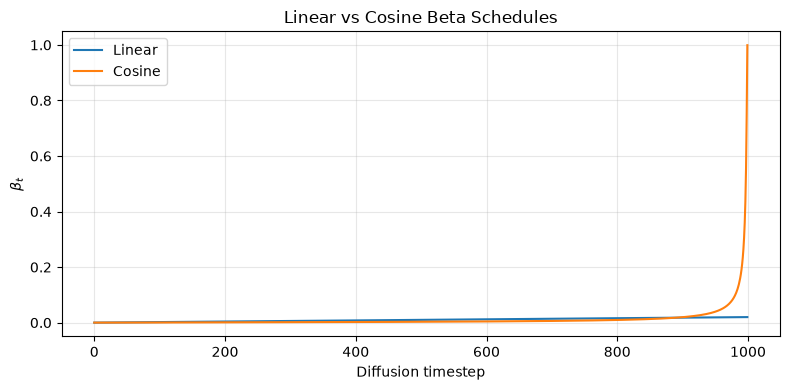

In [18]:
# Move schedule values to CPU for plotting.
t = np.arange(timesteps)

plt.figure(figsize=(8, 4))

plt.plot(t, linear_betas.detach().cpu(), label="Linear")
plt.plot(t, cosine_betas.detach().cpu(), label="Cosine")

plt.xlabel("Diffusion timestep")
plt.ylabel(r"$\beta_t$")
plt.title("Linear vs Cosine Beta Schedules")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.2 Compare cumulative signal retention

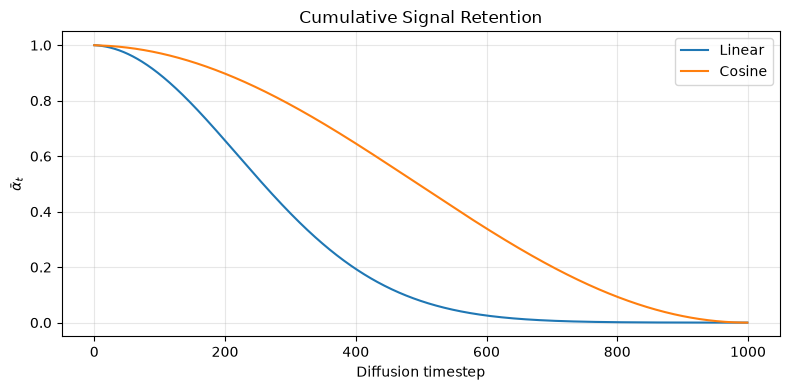

In [19]:
plt.figure(figsize=(8, 4))

plt.plot(
    t,
    linear_alpha_bars.detach().cpu(),
    label="Linear"
)

plt.plot(
    t,
    cosine_alpha_bars.detach().cpu(),
    label="Cosine"
)

plt.xlabel("Diffusion timestep")
plt.ylabel(r"$\bar{\alpha}_t$")
plt.title("Cumulative Signal Retention")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3 Numerical checks
alpha_bar must monotonically decrease.

In [20]:
def validate_schedule(name, betas, alpha_bars):
    assert len(betas) == timesteps
    assert len(alpha_bars) == timesteps

    assert torch.all(torch.isfinite(betas))
    assert torch.all(torch.isfinite(alpha_bars))

    assert torch.all((betas > 0) & (betas < 1))
    assert torch.all(alpha_bars[1:] <= alpha_bars[:-1])

    print(
        f"{name:<8} | "
        f"alpha_bar start: {alpha_bars[0].item():.6f} | "
        f"alpha_bar end: {alpha_bars[-1].item():.8f}"
    )


validate_schedule(
    "Linear",
    linear_betas,
    linear_alpha_bars
)

validate_schedule(
    "Cosine",
    cosine_betas,
    cosine_alpha_bars
)

print("\nBoth schedules passed validation.")

Linear   | alpha_bar start: 0.999900 | alpha_bar end: 0.00004036
Cosine   | alpha_bar start: 0.999900 | alpha_bar end: 0.00000000

Both schedules passed validation.


## 6. Shared Forward Diffusion

The DDPM forward process constructs a noisy sample $x_t$ directly from a clean image $x_0$ using:

$$
x_t =
\sqrt{\bar{\alpha}_t}x_0
+
\sqrt{1-\bar{\alpha}_t}\epsilon,
\qquad
\epsilon \sim \mathcal{N}(0,I)
$$

where $\bar{\alpha}_t$ is determined by the selected noise schedule.

The same forward-diffusion implementation is shared by both Project 7 models. Only the schedule coefficients supplied to the function differ between the linear and cosine experiments.

This maintains the noise schedule as the primary experimental variable.

### 6.1 Shared Schedule Representation

The forward and reverse DDPM processes require several coefficients derived from the selected beta schedule.

A shared helper constructs these coefficients from any supplied sequence of beta values. This allows the remaining DDPM implementation to operate on a common schedule representation rather than maintaining separate linear and cosine versions of each coefficient.

The two models therefore share the same diffusion implementation while receiving different schedule coefficients.

In [21]:
def prepare_diffusion_coefficients(betas):
    """
    Precompute coefficients required by the DDPM forward and reverse processes.
    """
    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)

    return {
        "betas": betas,
        "alphas": alphas,
        "alpha_bars": alpha_bars,
        "sqrt_alpha_bars": torch.sqrt(alpha_bars),
        "sqrt_one_minus_alpha_bars": torch.sqrt(1.0 - alpha_bars),
        "sqrt_recip_alphas": torch.sqrt(1.0 / alphas),
    }


linear_schedule = prepare_diffusion_coefficients(linear_betas)
cosine_schedule = prepare_diffusion_coefficients(cosine_betas)

### 6.2 Validate Shared Schedule Representation

Both schedule representations are checked for consistent dimensions and finite coefficient values before they are used by the shared diffusion functions.

In [22]:
print("Linear schedule:")
for key, value in linear_schedule.items():
    print(f"  {key:<30} {tuple(value.shape)}")

print("\nCosine schedule:")
for key, value in cosine_schedule.items():
    print(f"  {key:<30} {tuple(value.shape)}")


assert linear_schedule.keys() == cosine_schedule.keys()

for schedule in (linear_schedule, cosine_schedule):
    for name, values in schedule.items():
        assert values.shape == (timesteps,), (
            f"Unexpected shape for {name}: {values.shape}"
        )
        assert torch.all(torch.isfinite(values)), (
            f"Non-finite values found in {name}"
        )

print("\nShared schedule representation validated.")

Linear schedule:
  betas                          (1000,)
  alphas                         (1000,)
  alpha_bars                     (1000,)
  sqrt_alpha_bars                (1000,)
  sqrt_one_minus_alpha_bars      (1000,)
  sqrt_recip_alphas              (1000,)

Cosine schedule:
  betas                          (1000,)
  alphas                         (1000,)
  alpha_bars                     (1000,)
  sqrt_alpha_bars                (1000,)
  sqrt_one_minus_alpha_bars      (1000,)
  sqrt_recip_alphas              (1000,)

Shared schedule representation validated.


### 6.3 Extract Timestep Coefficients

During training, each image in a batch may be assigned a different diffusion timestep.

The `extract` helper selects the corresponding schedule coefficient for each sample and reshapes the result so that it can be broadcast across the image dimensions.

In [23]:
# ADAPTED FROM: TUTORIAL 9 SOLUTION
def extract(values, timesteps_batch, x_shape):
    batch_size = timesteps_batch.shape[0]

    out = values.gather(0, timesteps_batch)

    return out.reshape(
        batch_size,
        *((1,) * (len(x_shape) - 1))
    )

### 6.4 Shared Forward Sampling

The tutorial forward-sampling process is adapted so that a complete schedule representation is supplied explicitly.

This allows the same `q_sample` implementation to be used for both the linear and cosine DDPMs without duplicating the diffusion logic.

In [24]:
def q_sample(x_start, t, schedule, noise=None):
    """
    Sample x_t directly from x_0 using the supplied diffusion schedule.
    """
    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha_bar_t = extract(
        schedule["sqrt_alpha_bars"],
        t,
        x_start.shape
    )

    sqrt_one_minus_alpha_bar_t = extract(
        schedule["sqrt_one_minus_alpha_bars"],
        t,
        x_start.shape
    )

    x_noisy = (
        sqrt_alpha_bar_t * x_start
        + sqrt_one_minus_alpha_bar_t * noise
    )

    return x_noisy, noise

### 6.5 Validate Shared Forward Diffusion

The shared forward-sampling function is tested using both schedules to confirm that it preserves the expected image dimensions and produces finite outputs.

In [25]:
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images[:8].to(device)

sample_t = torch.full(
    (sample_images.shape[0],),
    500,
    device=device,
    dtype=torch.long
)

linear_noisy, _ = q_sample(
    sample_images,
    sample_t,
    linear_schedule
)

cosine_noisy, _ = q_sample(
    sample_images,
    sample_t,
    cosine_schedule
)

print(f"Original: {sample_images.shape}")
print(f"Linear:   {linear_noisy.shape}")
print(f"Cosine:   {cosine_noisy.shape}")

assert linear_noisy.shape == sample_images.shape
assert cosine_noisy.shape == sample_images.shape

assert torch.all(torch.isfinite(linear_noisy))
assert torch.all(torch.isfinite(cosine_noisy))

print("\nForward diffusion validation passed.")

Original: torch.Size([8, 1, 20, 20])
Linear:   torch.Size([8, 1, 20, 20])
Cosine:   torch.Size([8, 1, 20, 20])

Forward diffusion validation passed.


### 6.6 Forward-Process Comparison

To visualise the effect of the two schedules, the same clean image is diffused at selected timesteps using both the linear and cosine schedules.

The same Gaussian noise is reused for corresponding linear and cosine samples so that differences in the resulting images are attributable to the noise schedule rather than different random noise draws.

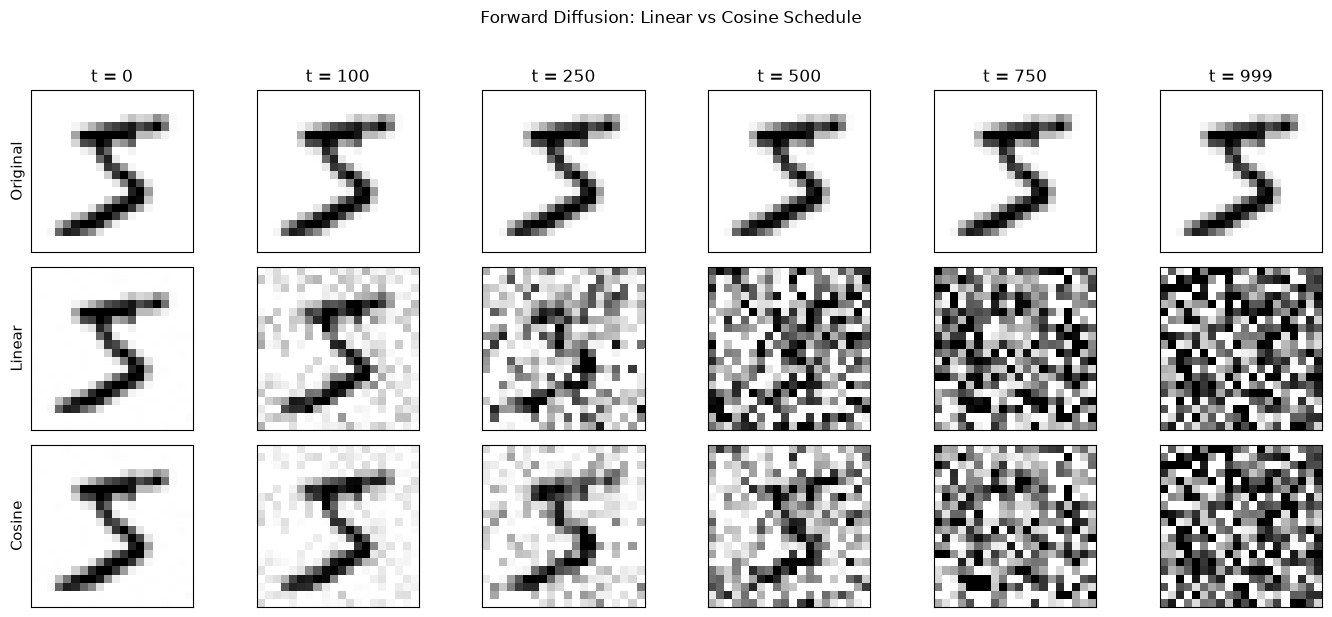

In [26]:
# Select one example image.
x_start = train_images_scaled[0:1].to(device)

comparison_timesteps = [0, 100, 250, 500, 750, 999]

# Use the same random sequence for reproducible visualisation.
torch.manual_seed(SEED)

fig, axes = plt.subplots(
    3,
    len(comparison_timesteps),
    figsize=(14, 6)
)

for col, timestep in enumerate(comparison_timesteps):
    t = torch.tensor(
        [timestep],
        device=device,
        dtype=torch.long
    )

    # Same noise is supplied to both schedules.
    shared_noise = torch.randn_like(x_start)

    linear_noisy, _ = q_sample(
        x_start,
        t,
        linear_schedule,
        noise=shared_noise
    )

    cosine_noisy, _ = q_sample(
        x_start,
        t,
        cosine_schedule,
        noise=shared_noise
    )

    axes[0, col].imshow(
        x_start[0, 0].detach().cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    axes[1, col].imshow(
        linear_noisy[0, 0].detach().cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    axes[2, col].imshow(
        cosine_noisy[0, 0].detach().cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    axes[0, col].set_title(f"t = {timestep}")

# Hide ticks rather than whole axes, so the row labels remain visible.
row_labels = ["Original", "Linear", "Cosine"]

for row, label in enumerate(row_labels):
    for col in range(len(comparison_timesteps)):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

    axes[row, 0].set_ylabel(label, fontsize=11)

plt.suptitle(
    "Forward Diffusion: Linear vs Cosine Schedule",
    y=1.02
)

plt.tight_layout()
plt.show()

## 7. Conditional U-Net

Both DDPM experiments use the same conditional U-Net architecture adapted from the Week 9 tutorial.

The model receives:

- the noisy image $x_t$;
- the diffusion timestep $t$; and
- the target digit class $y$.

The timestep and class are embedded and combined into a conditioning representation that is injected throughout the encoder, bottleneck and decoder. The network outputs a tensor with the same dimensions as the input image, representing its prediction $\hat{\epsilon}$ of the Gaussian noise present in $x_t$.

The supplied custom MNIST images have dimensions $20 \times 20$. No architectural resizing is required because the two pooling operations reduce the spatial dimensions from $20 \rightarrow 10 \rightarrow 5$, and the corresponding upsampling operations restore them from $5 \rightarrow 10 \rightarrow 20$.

The same architecture is used for both the linear and cosine schedule models so that the noise schedule remains the primary experimental variable.

### 7.1 Convolutional Block

The convolutional block from the tutorial 9 is retained as the basic feature-extraction component of the conditional U-Net.

In [27]:
# CITE: TUTORIAL 9 SOLUTION
channels = IMAGE_CHANNELS

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)

### 7.2 Conditional U-Net Architecture

The tutorial conditional U-Net combines timestep and class embeddings before injecting the resulting conditioning information throughout the network.

For a batch of noisy images:

```text
x_t + timestep t + class y
            ↓
     conditional U-Net
            ↓
   predicted noise ε̂
```

The total number of diffusion timesteps is stored on the model so that the timestep embedding is normalised consistently at training and inference time, rather than depending on a notebook-level global variable.

In [28]:
# CITE: TUTORIAL 9 SOLUTION
class UNet_cond(nn.Module):
    def __init__(self, ch=32, n_classes=10, timesteps=TIMESTEPS):
        super().__init__()

        # Retained so the timestep embedding is normalised against the
        # number of diffusion steps the model was trained with.
        self.timesteps = timesteps

        # Encoder
        self.enc1 = ConvBlock(channels, ch)
        self.enc2 = ConvBlock(ch, ch * 2)

        # Bottleneck
        self.bot = ConvBlock(ch * 2, ch * 2)

        # Decoder
        self.dec2 = ConvBlock(ch * 2 + ch * 2, ch)
        self.dec1 = ConvBlock(ch + ch, ch)

        # Final noise prediction
        self.final = nn.Conv2d(ch, channels, 1)

        # Timestep embedding
        self.time_mlp = nn.Sequential(
            nn.Linear(1, ch),
            nn.ReLU(),
            nn.Linear(ch, ch)
        )

        # Class embedding
        self.class_emb = nn.Embedding(n_classes, ch)

        # Projections to match channel dimensions
        self.to_e1 = nn.Conv2d(ch, ch, 1)
        self.to_e2 = nn.Conv2d(ch, ch * 2, 1)
        self.to_b = nn.Conv2d(ch, ch * 2, 1)
        self.to_d2 = nn.Conv2d(ch, ch, 1)
        self.to_d1 = nn.Conv2d(ch, ch, 1)

        self.pool = nn.AvgPool2d(2)
        self.upsample = nn.Upsample(
            scale_factor=2,
            mode="nearest"
        )

    def forward(self, x, t, y):
        # Normalised timestep embedding
        t = t.float().unsqueeze(-1) / self.timesteps
        t_emb = self.time_mlp(t).unsqueeze(-1).unsqueeze(-1)

        # Class embedding
        y_emb = self.class_emb(y).unsqueeze(-1).unsqueeze(-1)

        # Combined conditioning
        cond_emb = t_emb + y_emb

        # Encoder
        e1 = self.enc1(x) + self.to_e1(cond_emb)
        e2 = self.enc2(self.pool(e1)) + self.to_e2(cond_emb)

        # Bottleneck
        b = self.bot(self.pool(e2)) + self.to_b(cond_emb)

        # Decoder
        d2 = self.upsample(b)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2) + self.to_d2(cond_emb)

        d1 = self.upsample(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1) + self.to_d1(cond_emb)

        return self.final(d1)

### 7.3 Architecture Validation

Before training, the conditional U-Net is tested using a batch from the custom dataset.

The model must accept $20 \times 20$ noisy images together with timestep and class conditions and return a predicted-noise tensor with exactly the same shape as the input.

In [29]:
# Instantiate a temporary model for architecture validation.
arch_model = UNet_cond(
    ch=UNET_CHANNELS,
    n_classes=NUM_CLASSES
).to(device)

# Obtain a small batch from the custom dataset. Distinct names are used so
# that the dataset-level test tensors are not overwritten.
arch_images, arch_labels = next(iter(train_loader))

arch_images = arch_images[:8].to(device)
arch_labels = arch_labels[:8].to(device)

# Use different diffusion timesteps across the batch.
arch_timesteps = torch.randint(
    0,
    timesteps,
    (arch_images.shape[0],),
    device=device,
    dtype=torch.long
)

# Produce noisy inputs using one valid schedule.
arch_noisy, arch_noise = q_sample(
    arch_images,
    arch_timesteps,
    linear_schedule
)

# Predict the noise.
with torch.no_grad():
    predicted_noise = arch_model(
        arch_noisy,
        arch_timesteps,
        arch_labels
    )

print(f"Clean images:    {arch_images.shape}")
print(f"Noisy images:    {arch_noisy.shape}")
print(f"True noise:      {arch_noise.shape}")
print(f"Predicted noise: {predicted_noise.shape}")

assert predicted_noise.shape == arch_noise.shape
assert predicted_noise.shape == arch_images.shape
assert torch.all(torch.isfinite(predicted_noise))

# The dataset tensors must be untouched by this validation step.
assert test_images.shape[0] == len(test_dataset)

print("\nConditional U-Net validation passed.")

Clean images:    torch.Size([8, 1, 20, 20])
Noisy images:    torch.Size([8, 1, 20, 20])
True noise:      torch.Size([8, 1, 20, 20])
Predicted noise: torch.Size([8, 1, 20, 20])

Conditional U-Net validation passed.


### 7.4 Model Summary

In [30]:
total_params = sum(
    p.numel() for p in arch_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in arch_model.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")



Total parameters:     221,569
Trainable parameters: 221,569


In [31]:
# Free the temporary validation model. Optional, and only relevant if
# notebook runtime memory becomes constrained.

# del arch_model

# if torch.cuda.is_available():
#     torch.cuda.empty_cache()

## 8. Shared Training Implementation

Both DDPM models are trained using the same noise-prediction objective and training procedure.

For each training batch:

1. a random diffusion timestep $t$ is sampled for each image;
2. Gaussian noise $\epsilon$ is sampled;
3. the selected schedule is used to construct the noisy image $x_t$;
4. the conditional U-Net predicts the added noise $\hat{\epsilon}$ from $(x_t, t, y)$;
5. mean squared error is calculated between the true and predicted noise; and
6. the model parameters are updated through backpropagation.

The training objective is:

$$
L = \operatorname{MSE}(\epsilon, \hat{\epsilon})
$$

A shared training function is used for both experiments. The model instance and diffusion schedule are supplied as arguments, allowing the linear and cosine models to be trained under otherwise comparable conditions.

### 8.1 Training Configuration

Training settings are shared between the linear and cosine experiments to maintain a controlled comparison.

The conditional U-Net width, learning rate and training duration follow the Week 9 tutorial configuration. Both models will be independently initialised and trained using the same settings.

In [32]:
# ADAPTED FROM: TUTORIAL 9 SOLUTION
# UNET_CHANNELS, BATCH_SIZE and the diffusion settings are defined in the
# shared configuration cell in Section 1.2.

EPOCHS = 150
LEARNING_RATE = 2e-4

print("Training configuration")
print(f"  Epochs:          {EPOCHS}")
print(f"  Batch size:       {BATCH_SIZE}")
print(f"  Learning rate:    {LEARNING_RATE}")
print(f"  U-Net channels:   {UNET_CHANNELS}")
print(f"  Diffusion steps:  {timesteps}")
print(f"  Classes:          {NUM_CLASSES}")
print(f"  Device:           {device}")

Training configuration
  Epochs:          150
  Batch size:       128
  Learning rate:    0.0002
  U-Net channels:   32
  Diffusion steps:  1000
  Classes:          10
  Device:           cuda


### 8.2 Training Function

The shared training function accepts a model and diffusion schedule as arguments.

This keeps the training procedure identical between experiments while allowing either the linear or cosine schedule to determine how each noisy training sample is constructed. Training loss and runtime are retained for later comparison.

In [33]:
def train_ddpm(
    model,
    train_loader,
    schedule,
    epochs,
    learning_rate,
    device,
    verbose=True
):
    """
    Train a conditional DDPM to predict the Gaussian noise added
    during the forward diffusion process.
    """
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = []
    start_time = time.perf_counter()

    # Taken from the supplied schedule so that training cannot silently
    # disagree with the number of steps the schedule defines.
    n_steps = schedule["betas"].shape[0]

    model.train()

    for epoch in range(epochs):
        epoch_loss = 0.0

        for x_start, labels in train_loader:
            x_start = x_start.to(device)
            labels = labels.to(device)

            batch_size = x_start.shape[0]

            # Sample a random timestep for each image.
            t = torch.randint(
                0,
                n_steps,
                (batch_size,),
                device=device,
                dtype=torch.long
            )

            # Apply forward diffusion using the selected schedule.
            x_noisy, noise = q_sample(
                x_start,
                t,
                schedule
            )

            # Predict the noise added to the images.
            predicted_noise = model(
                x_noisy,
                t,
                labels
            )

            # Noise-prediction objective.
            loss = F.mse_loss(
                predicted_noise,
                noise
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * batch_size

        mean_epoch_loss = epoch_loss / len(train_loader.dataset)
        history.append(mean_epoch_loss)

        if verbose:
            elapsed = time.perf_counter() - start_time
            avg_epoch_time = elapsed / (epoch + 1)
            remaining = avg_epoch_time * (epochs - epoch - 1)

            elapsed_str = time.strftime(
                "%H:%M:%S",
                time.gmtime(elapsed)
            )

            eta_str = time.strftime(
                "%H:%M:%S",
                time.gmtime(remaining)
            )
            
            print(
                f"Epoch {epoch + 1:03d}/{epochs} | "
                f"Loss: {mean_epoch_loss:.6f} | "
                f"Elapsed: {elapsed_str} | "
                f"ETA: {eta_str}"
            )

    elapsed_time = time.perf_counter() - start_time

    return {
        "loss": history,
        "training_time_seconds": elapsed_time,
        "epochs": epochs,
        "learning_rate": learning_rate,
    }

### 8.3 Training Loop Validation

Before beginning the full experiments, the shared training function is tested on a small subset of the training data for one epoch.

This validation confirms that forward diffusion, conditional noise prediction, loss calculation and backpropagation operate together correctly without modifying either of the final experimental models.

In [34]:
# Small subset used only to validate the training pipeline.
validation_size = min(512, len(train_dataset))

validation_dataset = torch.utils.data.Subset(
    train_dataset,
    range(validation_size)
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_model = UNet_cond(
    ch=UNET_CHANNELS,
    n_classes=NUM_CLASSES
).to(device)

validation_history = train_ddpm(
    model=validation_model,
    train_loader=validation_loader,
    schedule=linear_schedule,
    epochs=1,
    learning_rate=LEARNING_RATE,
    device=device
)

print(
    f"\nValidation completed in "
    f"{validation_history['training_time_seconds']:.2f} seconds."
)

assert len(validation_history["loss"]) == 1
assert np.isfinite(validation_history["loss"][0])

print("Training loop validation passed.")

Epoch 001/1 | Loss: 1.064504 | Elapsed: 00:00:00 | ETA: 00:00:00

Validation completed in 0.18 seconds.
Training loop validation passed.


## 9. Train Model A — Linear Schedule

Model A is trained using the baseline linear noise schedule adapted from the Week 9 tutorial.

A fresh conditional U-Net is initialised using a fixed random seed. The model is then trained on the complete custom MNIST training set using the shared DDPM training procedure.

The resulting model weights and training history are saved for later inference and comparison with the cosine-schedule model.

### 9.1 Initialise Model A

In [35]:
# Reset random state before model initialisation.
reset_random_seeds()

linear_model = UNet_cond(
    ch=UNET_CHANNELS,
    n_classes=NUM_CLASSES
).to(device)

# Preserve Model A's initial weights so Model B can be
# verified against exactly the same initialisation.
initial_model_state = copy.deepcopy(
    linear_model.state_dict()
)

print(
    f"Linear model parameters: "
    f"{sum(p.numel() for p in linear_model.parameters()):,}"
)

Linear model parameters: 221,569


### 9.2 Linear-Schedule Training

The baseline model is trained for the configured number of epochs using the linear diffusion schedule.

Training loss and total training time are recorded for later diagnostics and comparison.

In [36]:
# Reset the random state immediately before training so that Model A and
# Model B receive equivalent DataLoader shuffling, sampled timesteps and
# Gaussian noise sequences. Model initialisation above consumes a different
# number of random draws for each model, so the reset must happen here.
reset_random_seeds()

linear_history = train_ddpm(
    model=linear_model,
    train_loader=train_loader,
    schedule=linear_schedule,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    device=device
)

print(
    f"\nLinear training complete."
    f"\nFinal loss: "
    f"{linear_history['loss'][-1]:.6f}"
    f"\nTraining time: "
    f"{linear_history['training_time_seconds']:.2f} seconds"
)

Epoch 001/150 | Loss: 0.284612 | Elapsed: 00:00:08 | ETA: 00:20:06
Epoch 002/150 | Loss: 0.100255 | Elapsed: 00:00:16 | ETA: 00:19:56
Epoch 003/150 | Loss: 0.076969 | Elapsed: 00:00:24 | ETA: 00:19:48
Epoch 004/150 | Loss: 0.067596 | Elapsed: 00:00:32 | ETA: 00:19:37
Epoch 005/150 | Loss: 0.061756 | Elapsed: 00:00:40 | ETA: 00:19:28
Epoch 006/150 | Loss: 0.057504 | Elapsed: 00:00:48 | ETA: 00:19:19
Epoch 007/150 | Loss: 0.054385 | Elapsed: 00:00:56 | ETA: 00:19:11
Epoch 008/150 | Loss: 0.051821 | Elapsed: 00:01:04 | ETA: 00:19:03
Epoch 009/150 | Loss: 0.049998 | Elapsed: 00:01:12 | ETA: 00:18:55
Epoch 010/150 | Loss: 0.047765 | Elapsed: 00:01:20 | ETA: 00:18:48
Epoch 011/150 | Loss: 0.047121 | Elapsed: 00:01:28 | ETA: 00:18:40
Epoch 012/150 | Loss: 0.045267 | Elapsed: 00:01:36 | ETA: 00:18:32
Epoch 013/150 | Loss: 0.044316 | Elapsed: 00:01:44 | ETA: 00:18:24
Epoch 014/150 | Loss: 0.043247 | Elapsed: 00:01:52 | ETA: 00:18:16
Epoch 015/150 | Loss: 0.042823 | Elapsed: 00:02:00 | ETA: 00:1

### 9.3 Save Linear Model Checkpoint

The trained linear-schedule model is saved immediately after training so that it can be loaded independently by the Task 2 inference notebook without retraining.

In [37]:
linear_checkpoint_path = CHECKPOINT_DIR / "ddpm_linear.pt"

torch.save(
    {
        "model_state_dict": linear_model.state_dict(),
        "schedule": "linear",
        "timesteps": timesteps,
        "unet_channels": UNET_CHANNELS,
        "num_classes": NUM_CLASSES,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "training_history": linear_history,
    },
    linear_checkpoint_path
)

print(f"Saved linear checkpoint to: {linear_checkpoint_path}")

Saved linear checkpoint to: checkpoints/ddpm_linear.pt


## 10. Train Model B — Cosine Schedule

Model B uses the same conditional U-Net architecture, dataset and training configuration as Model A, but replaces the linear noise schedule with the cosine schedule implemented for Project 7.

The random seed is reset before model initialisation so that both models begin with identical initial network weights, and reset again immediately before the training call so that both runs receive equivalent DataLoader shuffling, sampled timesteps and Gaussian noise sequences. This reduces variation unrelated to the experimental noise schedule.

Given the amount of training compute to occur prior, let's assure the file exists

In [38]:
assert linear_checkpoint_path.exists()

print(
    f"Linear checkpoint size: "
    f"{linear_checkpoint_path.stat().st_size / (1024 ** 2):.2f} MB"
)

print("Linear checkpoint verified.")

Linear checkpoint size: 0.86 MB
Linear checkpoint verified.


### 10.1 Verify Identical Initialisation

In [39]:
# Reset random state before Model B initialisation.
reset_random_seeds()

cosine_model = UNet_cond(
    ch=UNET_CHANNELS,
    n_classes=NUM_CLASSES
).to(device)

initialisation_matches = all(
    torch.equal(
        initial_model_state[name],
        cosine_model.state_dict()[name]
    )
    for name in initial_model_state
)

assert initialisation_matches

print("Model A and Model B initialisation matches.")

Model A and Model B initialisation matches.


### 10.2 Cosine-Schedule Training

The second model is trained using the same shared training procedure as Model A, with the cosine diffusion schedule supplied in place of the linear schedule.

Loss and total training time are recorded using the same diagnostics as the baseline experiment.

In [40]:
# Matches the reset performed before Model A's training call.
reset_random_seeds()

cosine_history = train_ddpm(
    model=cosine_model,
    train_loader=train_loader,
    schedule=cosine_schedule,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    device=device
)

print(
    f"\nCosine training complete."
    f"\nFinal loss: "
    f"{cosine_history['loss'][-1]:.6f}"
    f"\nTraining time: "
    f"{cosine_history['training_time_seconds']:.2f} seconds"
)

Epoch 001/150 | Loss: 0.349857 | Elapsed: 00:00:07 | ETA: 00:19:51
Epoch 002/150 | Loss: 0.134621 | Elapsed: 00:00:16 | ETA: 00:19:46
Epoch 003/150 | Loss: 0.106274 | Elapsed: 00:00:24 | ETA: 00:19:37
Epoch 004/150 | Loss: 0.093993 | Elapsed: 00:00:32 | ETA: 00:19:29
Epoch 005/150 | Loss: 0.086372 | Elapsed: 00:00:40 | ETA: 00:19:21
Epoch 006/150 | Loss: 0.081620 | Elapsed: 00:00:48 | ETA: 00:19:13
Epoch 007/150 | Loss: 0.078292 | Elapsed: 00:00:56 | ETA: 00:19:05
Epoch 008/150 | Loss: 0.075446 | Elapsed: 00:01:04 | ETA: 00:18:58
Epoch 009/150 | Loss: 0.073868 | Elapsed: 00:01:12 | ETA: 00:18:51
Epoch 010/150 | Loss: 0.071299 | Elapsed: 00:01:20 | ETA: 00:18:43
Epoch 011/150 | Loss: 0.070342 | Elapsed: 00:01:28 | ETA: 00:18:35
Epoch 012/150 | Loss: 0.068347 | Elapsed: 00:01:36 | ETA: 00:18:28
Epoch 013/150 | Loss: 0.067742 | Elapsed: 00:01:44 | ETA: 00:18:20
Epoch 014/150 | Loss: 0.066075 | Elapsed: 00:01:52 | ETA: 00:18:12
Epoch 015/150 | Loss: 0.065723 | Elapsed: 00:02:00 | ETA: 00:1

### 10.3 Save Model B

In [41]:
cosine_checkpoint_path = CHECKPOINT_DIR / "ddpm_cosine.pt"

torch.save(
    {
        "model_state_dict": cosine_model.state_dict(),
        "schedule": "cosine",
        "timesteps": timesteps,
        "unet_channels": UNET_CHANNELS,
        "num_classes": NUM_CLASSES,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "training_history": cosine_history,
    },
    cosine_checkpoint_path
)

assert cosine_checkpoint_path.exists()

print(f"Saved cosine checkpoint to: {cosine_checkpoint_path}")

print(
    f"Cosine checkpoint size: "
    f"{cosine_checkpoint_path.stat().st_size / (1024 ** 2):.2f} MB"
)

print("Cosine checkpoint verified.")

Saved cosine checkpoint to: checkpoints/ddpm_cosine.pt
Cosine checkpoint size: 0.86 MB
Cosine checkpoint verified.


## 11. Training Diagnostics

The training histories of the linear- and cosine-schedule models are compared to verify that both models trained successfully under the shared training configuration.

Training loss measures the U-Net's ability to predict the Gaussian noise added during forward diffusion. It is useful for assessing training behaviour, but does not by itself determine the quality of generated samples. Generation quality will be evaluated separately through inference.

**The two loss curves are not directly comparable.** The training objective averages the noise-prediction error over timesteps drawn uniformly from $[0, T)$, and each schedule assigns a different noise level — and therefore a different intrinsic difficulty — to the same timestep index. Because the cosine schedule retains more signal through the middle of the trajectory, a larger proportion of its sampled timesteps fall in the regime where predicting $\epsilon$ is harder, which raises its average loss.

A higher cosine loss is therefore an artefact of the schedule's timestep difficulty distribution, **not** evidence that the cosine model trained less successfully. Each curve should be read for its own convergence behaviour, and the comparison of model quality should rest on the generated samples produced in `main_report.ipynb`.

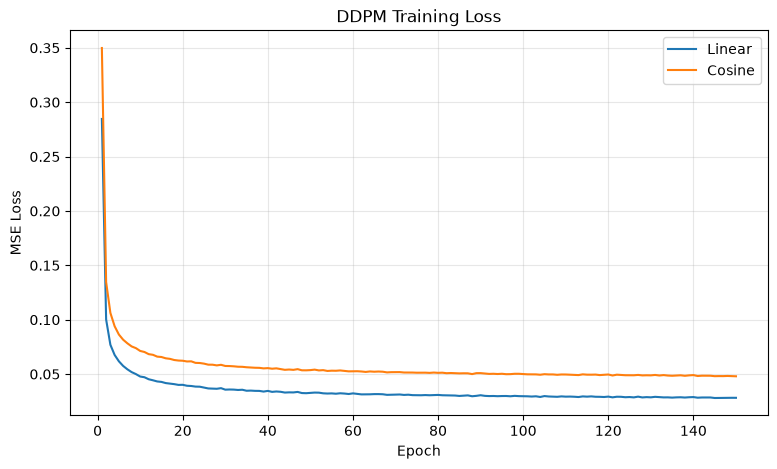

In [42]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(linear_history["loss"]) + 1),
    linear_history["loss"],
    label="Linear"
)

plt.plot(
    range(1, len(cosine_history["loss"]) + 1),
    cosine_history["loss"],
    label="Cosine"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("DDPM Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 11.1 Training Summary

In [43]:
print("Training Summary")
print("-" * 50)

print("Linear schedule")
print(f"  Epochs:        {len(linear_history['loss'])}")
print(f"  Initial loss:  {linear_history['loss'][0]:.6f}")
print(f"  Final loss:    {linear_history['loss'][-1]:.6f}")
print(
    f"  Training time: "
    f"{linear_history['training_time_seconds']:.2f} seconds"
)

print()

print("Cosine schedule")
print(f"  Epochs:        {len(cosine_history['loss'])}")
print(f"  Initial loss:  {cosine_history['loss'][0]:.6f}")
print(f"  Final loss:    {cosine_history['loss'][-1]:.6f}")
print(
    f"  Training time: "
    f"{cosine_history['training_time_seconds']:.2f} seconds"
)

Training Summary
--------------------------------------------------
Linear schedule
  Epochs:        150
  Initial loss:  0.284612
  Final loss:    0.028199
  Training time: 1211.42 seconds

Cosine schedule
  Epochs:        150
  Initial loss:  0.349857
  Final loss:    0.047993
  Training time: 1210.30 seconds


### 11.2 Checkpoint Verification

Both saved checkpoints are reloaded and inspected to confirm that the trained model weights and configuration required for later inference have been preserved successfully.

In [44]:
linear_checkpoint = torch.load(
    linear_checkpoint_path,
    map_location=device
)

cosine_checkpoint = torch.load(
    cosine_checkpoint_path,
    map_location=device
)

required_keys = {
    "model_state_dict",
    "schedule",
    "timesteps",
    "unet_channels",
    "num_classes",
    "epochs",
    "learning_rate",
    "training_history",
}

assert required_keys.issubset(linear_checkpoint.keys())
assert required_keys.issubset(cosine_checkpoint.keys())

assert linear_checkpoint["schedule"] == "linear"
assert cosine_checkpoint["schedule"] == "cosine"

assert linear_checkpoint["timesteps"] == timesteps
assert cosine_checkpoint["timesteps"] == timesteps

print("Linear checkpoint:")
print(f"  Schedule:   {linear_checkpoint['schedule']}")
print(f"  Epochs:     {linear_checkpoint['epochs']}")
print(f"  Timesteps:  {linear_checkpoint['timesteps']}")

print("\nCosine checkpoint:")
print(f"  Schedule:   {cosine_checkpoint['schedule']}")
print(f"  Epochs:     {cosine_checkpoint['epochs']}")
print(f"  Timesteps:  {cosine_checkpoint['timesteps']}")

print("\nCheckpoint verification passed.")

Linear checkpoint:
  Schedule:   linear
  Epochs:     150
  Timesteps:  1000

Cosine checkpoint:
  Schedule:   cosine
  Epochs:     150
  Timesteps:  1000

Checkpoint verification passed.


## 12. Reverse Sampling Sanity Check

Before completing the training notebook, a small conditional sampling experiment is performed to verify that both trained models can execute the DDPM reverse process successfully.

The reverse sampler is adapted from the Week 9 tutorial. Rather than relying on global diffusion coefficients, the sampler accepts a schedule explicitly. This allows the same implementation to be used with either the linear or cosine schedule.

This is a functional sanity check only. The full comparison of all 10 digit classes and 12 samples per class is performed separately in `main_report.ipynb`.

> **Note for the reduced-time-step experiment in Task 2.** `p_sample_cddpm` indexes `alphas[t]` and `betas[t]` one step at a time, so it assumes **consecutive** timesteps. Sampling with fewer steps therefore cannot be done by simply striding this loop. It requires either a respaced schedule, where the retained steps' $\bar{\alpha}$ values are used to derive a new, shorter sequence of betas, or a DDIM-style update that is explicitly non-Markovian. In addition, the model's timestep embedding must continue to be normalised against the $T$ it was trained with (`model.timesteps`), so a respaced sampler must pass the **original** timestep index to the model even while indexing the shortened schedule.

Conditional Revere Step

In [45]:
# ADAPTED FROM: TUTORIAL 9 SOLUTION
@torch.no_grad()
def p_sample_cddpm(model, x_t, t_index, y, schedule):
    """
    Perform one conditional DDPM reverse-diffusion step.
    """
    t = torch.full(
        (x_t.shape[0],),
        t_index,
        device=x_t.device,
        dtype=torch.long
    )

    beta = extract(
        schedule["betas"],
        t,
        x_t.shape
    )

    alpha = extract(
        schedule["alphas"],
        t,
        x_t.shape
    )

    alpha_bar = extract(
        schedule["alpha_bars"],
        t,
        x_t.shape
    )

    sigma = torch.sqrt(beta)

    predicted_noise = model(
        x_t,
        t,
        y
    )

    if t_index == 0:
        z = 0
    else:
        z = torch.randn_like(x_t)

    x_previous = (
        1.0 / torch.sqrt(alpha)
        * (
            x_t
            - beta
            / torch.sqrt(1.0 - alpha_bar)
            * predicted_noise
        )
        + sigma * z
    )

    return x_previous

Conditional Sampling Loop

In [46]:
# ADAPTED FROM: TUTORIAL 9 SOLUTION
@torch.no_grad()
def sample_cddpm(
    model,
    labels,
    schedule,
    seed=1337,
    channels=IMAGE_CHANNELS,
    image_size=IMAGE_SIZE
):
    """
    Generate conditional samples using the DDPM reverse process.

    The number of reverse steps is taken from the supplied schedule rather
    than a global, so the sampler stays consistent with whichever schedule
    it is given.
    """
    model.eval()

    torch.manual_seed(seed)

    n_samples = labels.shape[0]
    n_steps = schedule["betas"].shape[0]

    x = torch.randn(
        n_samples,
        channels,
        image_size,
        image_size,
        device=device
    )

    progress = tqdm(
        reversed(range(n_steps)),
        desc="Sampling",
        total=n_steps
    )

    for t_index in progress:
        x = p_sample_cddpm(
            model=model,
            x_t=x,
            t_index=t_index,
            y=labels,
            schedule=schedule
        )

    return x.clamp(-1, 1)

### 12.1 Conditional Generation Sanity Check

One sample is generated for each digit class (`0–9`) using both trained models.

The same random seed is supplied to both sampling runs so that they begin from the same initial Gaussian noise. This provides a controlled visual sanity check of the two reverse processes.

In [47]:
sanity_labels = torch.arange(
    NUM_CLASSES,
    device=device,
    dtype=torch.long
)

SAMPLING_SEED = 1337

linear_samples = sample_cddpm(
    model=linear_model,
    labels=sanity_labels,
    schedule=linear_schedule,
    seed=SAMPLING_SEED
)

cosine_samples = sample_cddpm(
    model=cosine_model,
    labels=sanity_labels,
    schedule=cosine_schedule,
    seed=SAMPLING_SEED
)

print("Linear samples:", linear_samples.shape)
print("Cosine samples:", cosine_samples.shape)

expected_shape = (
    NUM_CLASSES,
    IMAGE_CHANNELS,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert linear_samples.shape == expected_shape
assert cosine_samples.shape == expected_shape

assert torch.isfinite(linear_samples).all()
assert torch.isfinite(cosine_samples).all()

print("Conditional sampling validation passed.")

Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

Linear samples: torch.Size([10, 1, 20, 20])
Cosine samples: torch.Size([10, 1, 20, 20])
Conditional sampling validation passed.


Visualise

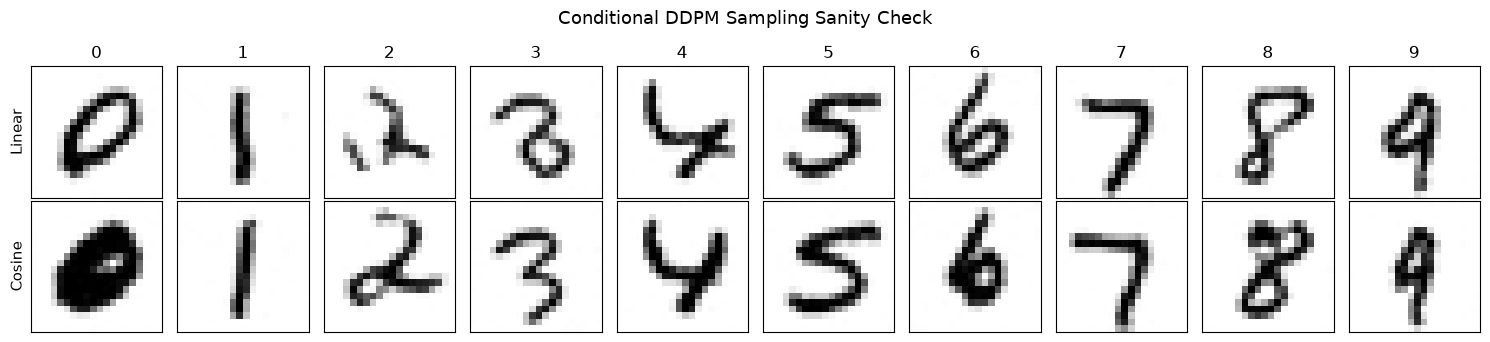

In [48]:
fig, axes = plt.subplots(
    2,
    NUM_CLASSES,
    figsize=(15, 3.5)
)

for digit in range(NUM_CLASSES):
    axes[0, digit].imshow(
        linear_samples[digit, 0].cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    axes[0, digit].set_title(str(digit))

    axes[1, digit].imshow(
        cosine_samples[digit, 0].cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

# Hide ticks rather than whole axes, so the row labels remain visible.
for row, label in enumerate(["Linear", "Cosine"]):
    for digit in range(NUM_CLASSES):
        axes[row, digit].set_xticks([])
        axes[row, digit].set_yticks([])

    axes[row, 0].set_ylabel(label, fontsize=11)

plt.suptitle(
    "Conditional DDPM Sampling Sanity Check",
    fontsize=13
)

plt.tight_layout()
plt.show()

## 13. Task 1 Completion

Two conditional DDPM models have been trained and saved using the supplied custom MNIST dataset:

- a baseline model using the tutorial linear beta schedule; and
- a comparison model using the implemented cosine beta schedule.

Both models use the same conditional U-Net architecture and shared training procedure. Training histories and checkpoints have been retained, and conditional reverse sampling has been verified successfully.

The saved checkpoints are used by `main_report.ipynb` for the formal inference comparison.